# NEBULA · Numerical Physics
**NASA Space Apps Challenge – Space Mission Design Game**

This notebook gathers **all the calculations and demonstrations** used by the NEBULA game. Every section follows the same pattern:

1. **Theory**: the physical law and where it comes from.
2. **Analytical calculation**: the closed-form formula.
3. **Numerical demonstration**: we simulate step by step and compare with the formula.
4. **Verification**: an `assert` confirms that both agree (✓).

To run it: menu *Runtime → Run all*. It only uses `numpy` and `matplotlib`, which already come with Colab.

**Contents**
0. Constants and utilities
1. Orbital mechanics (circular velocity, period, RK4, conservation of energy, vis-viva)
2. Hohmann transfer
3. Propulsion (Tsiolkovsky, numerical burn, chemical vs. ion engine)
4. Space power (E = P·t, eclipses, battery, solar flux)
5. Communications (latency, Friis equation, data rate)
6. The three NEBULA missions (Δv of AURORA, LUNARIS and ARES ECHO)
7. Resource optimization (J function, Pareto front, simulated annealing)
8. Uncertainty: reproducible random events and Monte Carlo
9. Summary of checks

## 0 · Constants and utilities

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import pi, sqrt, log, exp, asin

plt.rcParams.update({'figure.figsize': (8, 4.5), 'axes.grid': True, 'grid.alpha': .3, 'font.size': 11})

# Gravitational parameters μ = G·M  [m^3/s^2]
MU = {'earth': 3.986004418e14, 'moon': 4.9048695e12, 'mars': 4.282837e13, 'sun': 1.32712440018e20}
# Mean radii [m]
RAD = {'earth': 6.371e6, 'moon': 1.7374e6, 'mars': 3.3895e6}
AU = 1.495978707e11      # astronomical unit [m]
C  = 299_792_458.0       # speed of light [m/s]
G0 = 9.80665             # standard gravity [m/s^2]
KB = 1.380649e-23        # Boltzmann constant [J/K]
DAY = 86400.0

CHECKS = []   # here we store the result of every verification
def check(name, ok, detail=''):
    CHECKS.append((name, bool(ok), detail))
    print(('✓ ' if ok else '✗ ') + name + ('  —  ' + detail if detail else ''))
    assert ok, f'Check failed: {name}'

def kms(v): return f'{v/1000:,.3f} km/s'

## 1 · Orbital mechanics

### 1.1 Circular velocity
A circular orbit is a **free fall that never reaches the ground**: gravity provides exactly the centripetal force.

$$\frac{\mu}{r^2}=\frac{v^2}{r}\;\Rightarrow\; v=\sqrt{\frac{\mu}{r}},\qquad T=2\pi\sqrt{\frac{r^3}{\mu}}$$

If the orbit is raised, the spacecraft moves **slower**, but it covers a longer path, so the period grows.

r = 6.7710e+06 m
v = 7.673 km/s | T = 92.41 min | v_esc/v = 1.4142 (= √2)
✓ Circular v at 400 km ≈ 7.67 km/s (ISS value)  —  7672.6 m/s
✓ Period at 400 km ≈ 92.4 min  —  92.41 min
✓ v_esc = √2 · v_circ


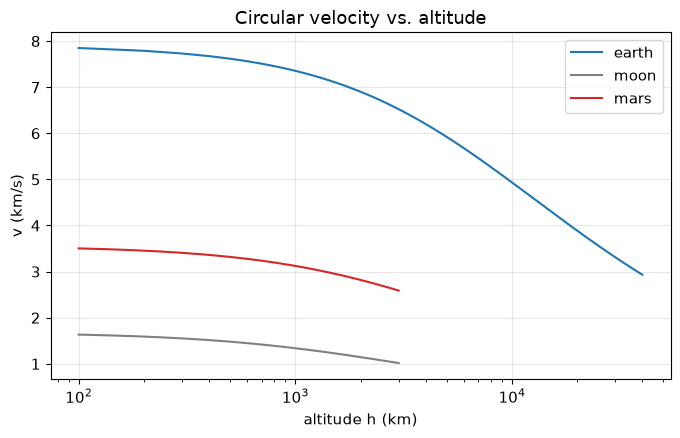

In [2]:
def v_circ(mu, r):   return sqrt(mu / r)
def period(mu, r):   return 2*pi*sqrt(r**3 / mu)
def v_esc(mu, r):    return sqrt(2*mu / r)

# Example: 400 km above the Earth (altitude of the ISS)
r = RAD['earth'] + 400e3
v = v_circ(MU['earth'], r); T = period(MU['earth'], r)
print('r =', f'{r:.4e} m')
print('v =', kms(v), '| T =', f'{T/60:.2f} min', '| v_esc/v =', f'{v_esc(MU["earth"], r)/v:.4f} (= √2)')

check('Circular v at 400 km ≈ 7.67 km/s (ISS value)', abs(v - 7672.6) < 5, f'{v:.1f} m/s')
check('Period at 400 km ≈ 92.4 min', abs(T/60 - 92.4) < 0.1, f'{T/60:.2f} min')
check('v_esc = √2 · v_circ', abs(v_esc(MU['earth'], r)/v - sqrt(2)) < 1e-12)

# Plot v(h) for three bodies
fig, ax = plt.subplots()
for body, col in [('earth', 'tab:blue'), ('moon', 'gray'), ('mars', 'tab:red')]:
    h = np.linspace(100e3, 40000e3 if body == 'earth' else 3000e3, 400)
    ax.plot(h/1e3, [v_circ(MU[body], RAD[body] + x)/1e3 for x in h], label=body, color=col)
ax.set_xlabel('altitude h (km)'); ax.set_ylabel('v (km/s)'); ax.set_title('Circular velocity vs. altitude'); ax.set_xscale('log'); ax.legend()
plt.show()

### 1.2 Numerical demonstration with Runge–Kutta 4 (RK4)
We do not simply trust the formula, so we integrate gravity step by step

$$\ddot{\vec r}=-\frac{\mu}{|\vec r|^3}\vec r$$

starting from the theoretical circular velocity. If the equation is correct, after one full lap the spacecraft must return to its starting point.

Position error after 1 lap (RK4, 4000 steps): 0.0000 m  (9.01e-11 % of r)
Final speed: 7672.5986 m/s  vs theoretical 7672.5986 m/s
✓ RK4 returns to the starting point (error < 1 m)  —  0.0000 m


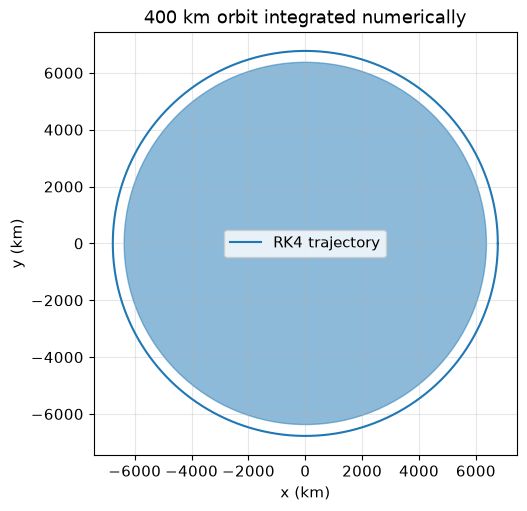

In [3]:
def accel(mu, s):
    x, y = s[0], s[1]; r3 = (x*x + y*y) ** 1.5
    return np.array([s[2], s[3], -mu*x/r3, -mu*y/r3])

def rk4_step(mu, s, dt):
    k1 = accel(mu, s); k2 = accel(mu, s + dt/2*k1); k3 = accel(mu, s + dt/2*k2); k4 = accel(mu, s + dt*k3)
    return s + dt/6*(k1 + 2*k2 + 2*k3 + k4)

def euler_step(mu, s, dt):
    return s + dt*accel(mu, s)

def one_lap(mu, r0, steps, method=rk4_step, save=False):
    s = np.array([r0, 0, 0, v_circ(mu, r0)]); dt = period(mu, r0)/steps; path = [s.copy()]
    for _ in range(steps):
        s = method(mu, s, dt)
        if save: path.append(s.copy())
    return s, np.array(path)

mu, r0 = MU['earth'], RAD['earth'] + 400e3
s, path = one_lap(mu, r0, 4000, save=True)
err = np.hypot(s[0] - r0, s[1])
print(f'Position error after 1 lap (RK4, 4000 steps): {err:.4f} m  ({err/r0*100:.2e} % of r)')
print(f'Final speed: {np.hypot(s[2], s[3]):.4f} m/s  vs theoretical {v_circ(mu, r0):.4f} m/s')
check('RK4 returns to the starting point (error < 1 m)', err < 1.0, f'{err:.4f} m')

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot(path[:, 0]/1e3, path[:, 1]/1e3, label='RK4 trajectory')
ax.add_patch(plt.Circle((0, 0), RAD['earth']/1e3, color='tab:blue', alpha=.5)); ax.set_aspect('equal')
ax.set_title('400 km orbit integrated numerically'); ax.set_xlabel('x (km)'); ax.set_ylabel('y (km)'); ax.legend(); plt.show()

### 1.3 How much does the method matter? Order of convergence
RK4 is **fourth order**: when the number of steps is doubled, the error should drop by ≈ 2⁴ = 16. Euler (first order) only divides it by ≈ 2.

In [ ]:
steps_list = [100, 200, 400, 800, 1600, 3200]
err_rk4, err_eu = [], []
for n in steps_list:
    s, _ = one_lap(mu, r0, n, rk4_step);   err_rk4.append(np.hypot(s[0]-r0, s[1]))
    s, _ = one_lap(mu, r0, n, euler_step); err_eu.append(np.hypot(s[0]-r0, s[1]))

fig, ax = plt.subplots()
ax.loglog(steps_list, err_eu, 'o-', label='Euler (order 1)'); ax.loglog(steps_list, err_rk4, 's-', label='RK4 (order 4)')
ax.set_xlabel('number of steps per lap'); ax.set_ylabel('position error (m)'); ax.set_title('Numerical convergence'); ax.legend(); plt.show()

# slope on a log-log scale = order of the method
order_rk4 = -np.polyfit(np.log(steps_list[:4]), np.log(err_rk4[:4]), 1)[0]
order_eu  = -np.polyfit(np.log(steps_list), np.log(err_eu), 1)[0]
print(f'Measured order RK4 ≈ {order_rk4:.2f} (expected 4) | Euler ≈ {order_eu:.2f} (expected 1)')
check('RK4 has order ≈ 4', 3.5 < order_rk4 < 4.6, f'{order_rk4:.2f}')
check('Euler has order ≈ 1', 0.8 < order_eu < 1.4, f'{order_eu:.2f}')

### 1.4 Conservation of energy and angular momentum
In a two-body problem the following are conserved

$$\varepsilon=\frac{v^2}{2}-\frac{\mu}{r}=-\frac{\mu}{2a},\qquad h=|\vec r\times\vec v|$$

They are a very demanding test of an integrator, since if they drift, the method is not useful for long missions.

In [ ]:
def energy(mu, s):  return 0.5*(s[2]**2 + s[3]**2) - mu/np.hypot(s[0], s[1])
def ang_mom(s):     return s[0]*s[3] - s[1]*s[2]

# elliptical orbit (perigee 400 km, apogee 12,000 km), 10 laps
rp, ra = RAD['earth'] + 400e3, RAD['earth'] + 12000e3
a = (rp + ra)/2; vp = sqrt(mu*(2/rp - 1/a))
Tel = 2*pi*sqrt(a**3/mu); s = np.array([rp, 0, 0, vp]); n = 20000; dt = 10*Tel/n
E0, h0 = energy(mu, s), ang_mom(s); dE, dh = [], []
for _ in range(n):
    s = rk4_step(mu, s, dt); dE.append(abs(energy(mu, s)/E0 - 1)); dh.append(abs(ang_mom(s)/h0 - 1))

fig, ax = plt.subplots()
ax.semilogy(np.linspace(0, 10, n), dE, label='|ΔE/E|'); ax.semilogy(np.linspace(0, 10, n), dh, label='|Δh/h|')
ax.set_xlabel('laps'); ax.set_title('Drift of the conserved quantities (RK4, 10 laps)'); ax.legend(); plt.show()
print(f'Maximum energy drift: {max(dE):.2e} | angular momentum drift: {max(dh):.2e}')
check('Energy is conserved (< 1e-6 over 10 laps)', max(dE) < 1e-6, f'{max(dE):.2e}')
check('Angular momentum is conserved (< 1e-9)', max(dh) < 1e-9, f'{max(dh):.2e}')

### 1.5 The vis-viva equation and Kepler's second law
In an elliptical orbit with semi-major axis $a$:

$$v=\sqrt{\mu\left(\frac{2}{r}-\frac{1}{a}\right)}$$

The spacecraft **speeds up when it gets closer and slows down when it moves away**. We check with the simulation that $v_p\,r_p=v_a\,r_a$ (conservation of $h$) and that the formula agrees with RK4.

In [ ]:
def vis_viva(mu, r, a): return sqrt(mu*(2/r - 1/a))
va = vis_viva(mu, ra, a)
print(f'a = {a/1e3:,.0f} km | e = {(ra-rp)/(ra+rp):.4f} | v_perigee = {kms(vp)} | v_apogee = {kms(va)}')
check("Kepler 2: vp·rp = va·ra", abs(vp*rp - va*ra)/(vp*rp) < 1e-12)

# we simulate half a period from perigee and compare the speed at apogee
s = np.array([rp, 0, 0, vp]); n = 20000; dt = (Tel/2)/n
for _ in range(n): s = rk4_step(mu, s, dt)
print(f'RK4 after T/2 → r = {np.hypot(s[0], s[1])/1e3:,.1f} km (expected {ra/1e3:,.1f}) | v = {np.hypot(s[2], s[3]):.3f} m/s (vis-viva {va:.3f})')
check('RK4 reaches apogee at T/2', abs(np.hypot(s[0], s[1]) - ra) < 5, f'Δr = {abs(np.hypot(s[0], s[1]) - ra):.3f} m')
check('RK4 speed at apogee = vis-viva', abs(np.hypot(s[2], s[3]) - va) < 0.01)

## 2 · Hohmann transfer
It is the most propellant-efficient way to move between two coplanar circular orbits using **two impulses**:

$$\Delta v_1=\sqrt{\frac{\mu}{r_1}}\left(\sqrt{\frac{2r_2}{r_1+r_2}}-1\right),\qquad
\Delta v_2=\sqrt{\frac{\mu}{r_2}}\left(1-\sqrt{\frac{2r_1}{r_1+r_2}}\right),\qquad
t=\pi\sqrt{\frac{a_t^3}{\mu}}$$

In [ ]:
def hohmann(mu, r1, r2):
    at = (r1 + r2)/2
    v1, v2 = v_circ(mu, r1), v_circ(mu, r2)
    vt1, vt2 = vis_viva(mu, r1, at), vis_viva(mu, r2, at)
    return dict(dv1=vt1 - v1, dv2=v2 - vt2, dv=(vt1 - v1) + (v2 - vt2), t=pi*sqrt(at**3/mu), at=at, vt1=vt1, vt2=vt2, v1=v1, v2=v2)

h = hohmann(MU['earth'], RAD['earth'] + 400e3, RAD['earth'] + 700e3)
print(f"AURORA 400→700 km: Δv1 = {h['dv1']:.2f} m/s, Δv2 = {h['dv2']:.2f} m/s, total = {h['dv']:.2f} m/s, time = {h['t']/60:.1f} min")

# explicit textbook formula vs. construction with vis-viva
r1, r2 = RAD['earth'] + 400e3, RAD['earth'] + 700e3; m = MU['earth']
dv1_book = sqrt(m/r1)*(sqrt(2*r2/(r1+r2)) - 1); dv2_book = sqrt(m/r2)*(1 - sqrt(2*r1/(r1+r2)))
check('Hohmann Δv: vis-viva = textbook formula', abs(h['dv1'] - dv1_book) < 1e-9 and abs(h['dv2'] - dv2_book) < 1e-9)

### 2.1 Numerical demonstration: we simulate the two impulses with RK4

In [ ]:
# Impulse 1 at r1 (tangential), coast for the transfer time, check that we reach r2 with speed vt2
s = np.array([r1, 0, 0, h['vt1']]); n = 20000; dt = h['t']/n
rs = []
for _ in range(n): s = rk4_step(m, s, dt); rs.append(np.hypot(s[0], s[1]))
print(f'After t_transfer: r = {np.hypot(s[0], s[1])/1e3:,.3f} km (target {r2/1e3:,.3f}) | v = {np.hypot(s[2], s[3]):.3f} m/s (vt2 = {h["vt2"]:.3f})')
check('The transfer ellipse reaches r2', abs(np.hypot(s[0], s[1]) - r2) < 1.0, f'{abs(np.hypot(s[0], s[1]) - r2):.4f} m')
# Impulse 2: we circularize and verify that the final orbit is circular (constant r)
s_c = np.array([s[0], s[1], s[2], s[3]]); rhat = s_c[:2]/np.hypot(*s_c[:2]); that = np.array([-rhat[1], rhat[0]])
vel = s_c[2:]; vel = vel/np.hypot(*vel)*v_circ(m, r2)  # new velocity = circular, same direction (tangent at apogee)
s_c[2:] = vel; rmin, rmax = 1e99, 0; dt = period(m, r2)/4000
for _ in range(4000): s_c = rk4_step(m, s_c, dt); rr = np.hypot(s_c[0], s_c[1]); rmin, rmax = min(rmin, rr), max(rmax, rr)
print(f'Final orbit: r between {rmin/1e3:,.3f} and {rmax/1e3:,.3f} km → eccentricity ≈ {(rmax-rmin)/(rmax+rmin):.2e}')
check('After the 2nd impulse the orbit is circular (e < 1e-5)', (rmax-rmin)/(rmax+rmin) < 1e-5)

# Δv cost as a function of the destination radius
rr2 = np.linspace(RAD['earth'] + 450e3, RAD['earth'] + 36000e3, 300)
plt.figure(); plt.plot((rr2 - RAD['earth'])/1e3, [hohmann(m, r1, x)['dv'] for x in rr2]); plt.xlabel('destination altitude (km)'); plt.ylabel('total Δv (m/s)')
plt.title('Hohmann Δv from 400 km'); plt.show()

## 3 · Propulsion

### 3.1 The Tsiolkovsky rocket equation
Without gravity or drag, with effective exhaust velocity $v_e = I_{sp}\,g_0$:

$$\Delta v=v_e\ln\frac{m_0}{m_f}\qquad\Longleftrightarrow\qquad m_{prop}=m_f\left(e^{\Delta v/v_e}-1\right)$$

Δv depends on the **logarithm** of the mass ratio, doubling the propellant does not double Δv.

In [ ]:
def dv_tsiolkovsky(ve, m0, mf): return ve*log(m0/mf)
def prop_needed(dv, ve, mf):    return mf*(exp(dv/ve) - 1)

def numerical_burn(m0, prop, F, ve, n=20000):
    '''Integrates dv = F/m dt with decreasing mass (constant mass flow F/ve).'''
    mdot = F/ve; tb = prop/mdot; dt = tb/n; m_, dv = m0, 0.0
    for _ in range(n):
        dv += F/m_*dt; m_ -= mdot*dt
    return dv, tb

ve = 315*G0   # bipropellant, Isp = 315 s
m0, prop = 500.0, 200.0
dv_t = dv_tsiolkovsky(ve, m0, m0 - prop)
dv_n, tb = numerical_burn(m0, prop, 450.0, ve)
print(f'Tsiolkovsky: {dv_t:.3f} m/s | Numerical simulation: {dv_n:.3f} m/s | burn time = {tb:.0f} s')
check('Numerical burn = Tsiolkovsky (< 0.01 %)', abs(dv_t - dv_n)/dv_t < 1e-4, f'diff {abs(dv_t - dv_n)/dv_t*100:.5f} %')
check('Round trip: prop_needed(Δv) = 200 kg', abs(prop_needed(dv_t, ve, m0 - prop) - prop) < 1e-9)

# diminishing returns
mf = 300; props = np.linspace(0, 1500, 300)
plt.figure()
for isp, name in [(220, 'Monopropellant (220 s)'), (315, 'Bipropellant (315 s)'), (2500, 'Ion (2500 s)')]:
    plt.plot(props, [dv_tsiolkovsky(isp*G0, mf + p, mf) for p in props], label=name)
plt.xlabel('propellant (kg)'); plt.ylabel('Δv (m/s)'); plt.title('Diminishing returns (dry mass 300 kg)'); plt.legend(); plt.show()

### 3.2 Low-thrust propulsion (ion engine): the spiral
An ion engine has a very high Isp but a tiny thrust, so it does not perform an instantaneous impulse but a slow **spiral**. For continuous tangential thrust between coplanar circular orbits (Edelbaum):

$$\Delta v_{spiral}=\sqrt{\frac{\mu}{r_1}}-\sqrt{\frac{\mu}{r_2}}$$

We can see that the Δv of a spiral (with constant thrust) is **not larger than the Hohmann Δv** for a small change, but it takes much longer: $t=m\,\Delta v/F$. We check it by integrating the equation of motion with tangential thrust.

In [ ]:
def spiral(mu, r1, r2, F, m0, ve, dt=20.0):
    '''Continuous tangential thrust until r2 is reached. Returns (time, Δv spent, final mass, trajectory).'''
    s = np.array([r1, 0, 0, v_circ(mu, r1)]); m_ = m0; t = 0.0; dv = 0.0; mdot = F/ve; path = []
    while np.hypot(s[0], s[1]) < r2 and t < 5e8:
        v = np.hypot(s[2], s[3]); a_t = F/m_
        def f(st, mm):
            x, y, vx, vy = st; r3 = (x*x + y*y)**1.5; vv = np.hypot(vx, vy)
            return np.array([vx, vy, -mu*x/r3 + a_t*vx/vv, -mu*y/r3 + a_t*vy/vv])
        k1 = f(s, m_); k2 = f(s + dt/2*k1, m_); k3 = f(s + dt/2*k2, m_); k4 = f(s + dt*k3, m_)
        s = s + dt/6*(k1 + 2*k2 + 2*k3 + k4); m_ -= mdot*dt; dv += a_t*dt; t += dt
        if int(t/dt) % 200 == 0: path.append(s[:2].copy())
    return t, dv, m_, np.array(path)

ve_ion = 2500*G0; F_ion = 0.05   # 50 mN, a small ion engine
r1, r2 = RAD['earth'] + 400e3, RAD['earth'] + 700e3
t_s, dv_s, m_f, path_s = spiral(MU['earth'], r1, r2, F_ion, 400.0, ve_ion, dt=30.0)
dv_theory = v_circ(MU['earth'], r1) - v_circ(MU['earth'], r2)
print(f'Spiral 400→700 km with 50 mN: time = {t_s/DAY:.1f} days | Δv spent = {dv_s:.1f} m/s | theory = {dv_theory:.1f} m/s | Hohmann = {hohmann(MU["earth"], r1, r2)["dv"]:.1f} m/s')
check('Spiral Δv ≈ √(μ/r1) − √(μ/r2) (error < 3 %)', abs(dv_s - dv_theory)/dv_theory < 0.03, f'{abs(dv_s - dv_theory)/dv_theory*100:.2f} %')
print(f'Propellant used: {400 - m_f:.3f} kg (a chemical engine would need ≈ {prop_needed(hohmann(MU["earth"], r1, r2)["dv"], 315*G0, 400):.1f} kg)')
plt.figure(figsize=(5.5, 5.5)); plt.plot(path_s[:, 0]/1e3, path_s[:, 1]/1e3); plt.gca().set_aspect('equal'); plt.title('Spiral with an ion engine'); plt.show()

## 4 · Space power

### 4.1 Energy = power × time and solar flux
$$E=P\cdot t,\qquad \Phi(d)=\Phi_{1\,AU}\left(\frac{1\,AU}{d}\right)^2$$

Far from the Sun, light falls with the **square** of the distance, so solar arrays generate much less (at Mars ≈ 43 %).

In [ ]:
FLUX_1AU = 1361.0  # W/m² (solar constant)
def flux(d_au): return FLUX_1AU/d_au**2
for name, d in [('Earth', 1.0), ('Mars', 1.5237), ('Jupiter', 5.203)]:
    print(f'{name:8s} {d:6.3f} AU → {flux(d):8.1f} W/m²  ({1/d**2*100:5.1f} % of what Earth receives)')
check('Mars receives ≈ 43 % of the sunlight Earth receives', abs(1/1.5237**2 - 0.431) < 0.002, f'{1/1.5237**2*100:.1f} %')
d = np.linspace(0.4, 6, 300); plt.figure(); plt.semilogy(d, flux(d)); plt.xlabel('distance from the Sun (AU)'); plt.ylabel('W/m²'); plt.title('Inverse-square law'); plt.show()

### 4.2 Eclipses
From a circular orbit of radius $r$ around a body of radius $R$, the fraction of each lap spent in shadow (distant Sun, orbit coplanar with the Sun direction) is

$$f_{ecl}=\frac{1}{\pi}\arcsin\!\left(\frac{R}{r}\right)$$

Numerical demonstration: we walk along the orbit and count how many points fall inside the shadow cylinder.

In [ ]:
def f_eclipse(R, r): return asin(R/r)/pi

def f_eclipse_num(R, r, n=200_000):
    th = np.linspace(0, 2*pi, n, endpoint=False)
    x, y = r*np.cos(th), r*np.sin(th)          # the Sun is in the +x direction (very far away)
    in_shadow = (x < 0) & (np.abs(y) < R)       # behind the planet and inside the shadow cylinder
    return in_shadow.mean()

for name, R, h_ in [('Earth 400 km', RAD['earth'], 400e3), ('Earth 700 km', RAD['earth'], 700e3), ('Moon 100 km', RAD['moon'], 100e3), ('Mars 300 km', RAD['mars'], 300e3)]:
    fa, fn = f_eclipse(R, R + h_), f_eclipse_num(R, R + h_)
    print(f'{name:15s} analytical = {fa*100:5.2f} %   numerical = {fn*100:5.2f} %')
    assert abs(fa - fn) < 1e-3
check('Eclipse fraction: analytical = numerical', True)

### 4.3 Energy balance and battery
We simulate, minute by minute, a satellite with solar arrays, a constant load and a battery. During eclipse the battery powers everything; if it runs out there is a **blackout**.

$$\frac{dE_{bat}}{dt}=P_{gen}(t)-P_{load},\quad P_{gen}=0\;\text{in eclipse}$$

In [ ]:
def simulate_battery(P_gen, P_load, cap_Wh, period_min, f_ecl, days=1, soc0=None):
    soc = cap_Wh*0.8 if soc0 is None else soc0; cap = cap_Wh*0.8   # we use an 80 % depth of discharge
    t = np.arange(0, int(days*1440)); in_ecl = (t % period_min) >= period_min*(1 - f_ecl)
    hist, blackout = [], 0
    for e in in_ecl:
        soc += ((0 if e else P_gen) - P_load)/60.0
        if soc < 0: blackout += 1; soc = 0
        soc = min(soc, cap); hist.append(soc)
    return t, np.array(hist), blackout

# Case 1: correctly sized
t, soc, blk = simulate_battery(P_gen=420, P_load=250, cap_Wh=350, period_min=98, f_ecl=0.36)
# Case 2: energy deficit
t2, soc2, blk2 = simulate_battery(P_gen=300, P_load=250, cap_Wh=100, period_min=98, f_ecl=0.36)
fig, ax = plt.subplots(); ax.plot(t/60, soc, label=f'Well sized (blackout: {blk} min)'); ax.plot(t2/60, soc2, label=f'Small battery (blackout: {blk2} min)')
ax.set_xlabel('hours'); ax.set_ylabel('battery energy (Wh)'); ax.set_title('Battery charge and discharge'); ax.legend(); plt.show()

# Verification with the net energy: E = (P_gen·(1 − f_ecl) − P_load)·t, without battery saturation
# we use a WHOLE number of orbits (15 × 100 min) so the balance is exact
n_orb = 15; per, fe = 100, 0.35; hours = n_orb*per/60   # eclipse of exactly 35 min per 100-min orbit
t3, soc3, _ = simulate_battery(P_gen=420, P_load=250, cap_Wh=1e9, period_min=per, f_ecl=fe, days=n_orb*per/1440, soc0=0)
E_sim = soc3[-1]; E_theory = (420*(1 - fe) - 250)*hours
print(f'Net energy in {n_orb} orbits ({hours:.1f} h) → theoretical = {E_theory:.1f} Wh | simulated = {E_sim:.1f} Wh (they agree because the eclipse lasts a whole number of minutes)')
check('Simulated net energy ≈ theoretical (< 3 %)', abs(E_sim - E_theory)/E_theory < 0.03, f'{abs(E_sim - E_theory)/E_theory*100:.2f} %')
check('The well-sized case has no blackout', blk == 0)
check('The small-battery case does have a blackout', blk2 > 0, f'{blk2} min')

## 5 · Communications

### 5.1 Latency
$$t=\frac{d}{c}$$
That is why **you cannot pilot a spacecraft millions of km away like a video game**.

In [ ]:
dist = {'Moon': 3.844e8, 'Sun–Earth L1 point': 1.5e9, 'Sun': AU, 'Mars (minimum)': 5.5e10, 'Mars (maximum)': 4.0e11, 'Jupiter': 6.3e11}
print(f'{"Destination":22s}{"distance (km)":>18s}{"one way":>14s}{"round trip":>16s}')
for k, d in dist.items():
    t = d/C
    s = f'{t:.2f} s' if t < 120 else f'{t/60:.1f} min'; s2 = f'{2*t:.2f} s' if 2*t < 120 else f'{2*t/60:.1f} min'
    print(f'{k:22s}{d/1e3:18,.0f}{s:>14s}{s2:>16s}')
check('Light takes ≈ 500 s to arrive from the Sun (worked example: 150 million km)', abs(AU/C - 499) < 1.5, f'{AU/C:.1f} s')
check('Moon ≈ 1.28 s', abs(3.844e8/C - 1.282) < 0.005)

### 5.2 The Friis equation and data rate
The received power falls with the square of the distance:

$$P_r=P_t\,G_t\,G_r\left(\frac{\lambda}{4\pi d}\right)^2$$

The maximum data rate that can be sustained for a required energy-per-bit to noise ratio $E_b/N_0$ and a link margin $M$ is

$$R=\frac{P_r}{k_B\,T_{sys}\,(E_b/N_0)\,M}$$

Gain of a parabolic antenna of diameter $D$: $G=\eta\left(\frac{\pi D}{\lambda}\right)^2$. We use X-band (≈ 8.4 GHz, λ ≈ 0.0357 m).

In [ ]:
LAMBDA = 0.0357  # X-band [m]
def dish_gain(D, lam=LAMBDA, eta=0.6): return eta*(pi*D/lam)**2
def friis_Pr(Pt, Gt, Gr, d, lam=LAMBDA): return Pt*Gt*Gr*(lam/(4*pi*d))**2
def data_rate_bps(Pt, Gt, Gr, d, T_sys, ebn0=1.78, margin=2.0, lam=LAMBDA):
    return friis_Pr(Pt, Gt, Gr, d, lam)/(KB*T_sys*ebn0*margin)

# Spacecraft antenna: 10 W transmitter, four options (gain in dB)
antennas = {'LGA (5 dBi)': 10**(5/10), 'MGA (18 dBi)': 10**(18/10), 'HGA (30 dBi)': 10**(30/10), 'DSA (40 dBi)': 10**(40/10)}
Gr_earth = dish_gain(34)   # 34 m antenna of the Deep Space Network
print(f'Ground station gain (34 m): {10*np.log10(Gr_earth):.1f} dBi')
d = np.logspace(5, 11.5, 300)   # distances in metres, from 100 km to about 300 million km
fig, ax = plt.subplots()
for name, G in antennas.items():
    ax.loglog(d/1e3, [data_rate_bps(10, G, Gr_earth, x, 30) for x in d], label=name)
for label, dd in [('Moon', 3.844e8), ('Mars', 2.2e11)]: ax.axvline(dd/1e3, color='k', ls=':', alpha=.6); ax.text(dd/1e3, ax.get_ylim()[0]*3, label, rotation=90, va='bottom')
ax.set_xlabel('distance (km)'); ax.set_ylabel('data rate (bit/s)'); ax.set_title('Data rate falls with d² (Friis)'); ax.legend(); plt.show()

# verification: doubling the distance reduces the rate to 1/4
G = antennas['HGA (30 dBi)']; r_a = data_rate_bps(10, G, Gr_earth, 1e9, 30); r_b = data_rate_bps(10, G, Gr_earth, 2e9, 30)
check('Double the distance → rate 4 times lower', abs(r_a/r_b - 4) < 1e-9, f'{r_a/r_b:.6f}')
check('+10 dB of gain → rate 10 times higher', abs(data_rate_bps(10, G*10, Gr_earth, 1e9, 30)/r_a - 10) < 1e-9)
print(f'HGA at the distance of the Moon: {data_rate_bps(10, G, Gr_earth, 3.844e8, 30)/1e6:,.1f} Mbit/s | at Mars (2.2e11 m): {data_rate_bps(10, G, Gr_earth, 2.2e11, 30)/1e3:,.2f} kbit/s')

## 6 · The three NEBULA missions
Here we recompute from scratch the **required Δv** of each mission with the same equations used by the game.

In [ ]:
# ---------- AURORA: Hohmann in Earth orbit 400 → 700 km ----------
hA = hohmann(MU['earth'], RAD['earth'] + 400e3, RAD['earth'] + 700e3)
print(f"AURORA  | Δv1 = {hA['dv1']:.1f} + Δv2 = {hA['dv2']:.1f} = {hA['dv']:.1f} m/s")

# ---------- LUNARIS: spacecraft already injected (TLI); lunar orbit insertion braking (LOI) ----------
r_ini = RAD['earth'] + 400e3; r_moon = 3.844e8
v_ap = vis_viva(MU['earth'], r_moon, (r_ini + r_moon)/2)      # speed on arrival at the Moon's orbit
v_moon = v_circ(MU['earth'], r_moon)                           # orbital speed of the Moon around the Earth
vinf_L = abs(v_moon - v_ap)                                    # speed relative to the Moon far from its gravity
rp_L = RAD['moon'] + 100e3                                     # 100 km circular orbit
def capture_dv(mu, rp, vinf, ra=None):
    vh = sqrt(vinf**2 + 2*mu/rp)                               # hyperbolic speed at periapsis
    vt = vis_viva(mu, rp, (rp + ra)/2) if ra else v_circ(mu, rp)
    return vh - vt
LOI = capture_dv(MU['moon'], rp_L, vinf_L)
print(f"LUNARIS | v∞ (Moon) = {vinf_L:.0f} m/s → LOI = {LOI:.1f} m/s | Earth–Moon transit ≈ {pi*sqrt(((r_ini + r_moon)/2)**3/MU['earth'])/DAY:.2f} days")
check('LOI ≈ 0.8–0.9 km/s (range of real missions)', 780 < LOI < 900, f'{LOI:.1f} m/s')

# ---------- ARES ECHO: heliocentric Hohmann Earth → Mars + capture into an elliptical orbit ----------
hM = hohmann(MU['sun'], AU, 1.5237*AU)
vinf_M = abs(v_circ(MU['sun'], 1.5237*AU) - hM['vt2'])
rp_M, ra_M = RAD['mars'] + 300e3, RAD['mars'] + 3.3e7
MOI = capture_dv(MU['mars'], rp_M, vinf_M, ra_M)
print(f"ARES    | Earth→Mars transit = {hM['t']/DAY:.1f} days | arrival v∞ = {vinf_M:.0f} m/s | MOI (elliptical) = {MOI:.1f} m/s")
check('Hohmann transit Earth→Mars ≈ 259 days', abs(hM['t']/DAY - 258.9) < 0.6, f"{hM['t']/DAY:.1f} d")
check('Elliptical Mars capture << circular capture', MOI < capture_dv(MU['mars'], rp_M, vinf_M))
print(f"        circular capture would be {capture_dv(MU['mars'], rp_M, vinf_M):.0f} m/s → the elliptical orbit saves {capture_dv(MU['mars'], rp_M, vinf_M) - MOI:.0f} m/s")

# Summary table with the propellant needed for a 300 kg dry spacecraft (bipropellant)
print('\nPropellant for a 300 kg dry spacecraft (Isp 315 s, +5 % margin + 60 m/s reserve):')
for name, dv in [('AURORA', hA['dv']), ('LUNARIS', LOI + 40), ('ARES ECHO', MOI + 40)]:
    dvr = dv*1.05 + 60; print(f'  {name:10s} required Δv = {dvr:7.1f} m/s → {prop_needed(dvr, 315*G0, 300):6.1f} kg')

### 6.1 Demonstration: the transit to Mars in a heliocentric simulation
We integrate the spacecraft in the Sun's gravitational field (RK4) starting from Earth's orbit with the Hohmann Δv, and check that it reaches Mars's orbit after ≈ 259 days.

In [ ]:
s = np.array([AU, 0, 0, hM['vt1']]); n = 40000; dt = hM['t']/n
path = [s[:2].copy()]
for _ in range(n): s = rk4_step(MU['sun'], s, dt); path.append(s[:2].copy())
path = np.array(path)
r_end = np.hypot(s[0], s[1])
print(f'Distance from the Sun at the end = {r_end/AU:.5f} AU (Mars = 1.5237 AU)')
check("The heliocentric simulation reaches Mars's orbit (< 1000 km)", abs(r_end - 1.5237*AU) < 1e6, f'{abs(r_end - 1.5237*AU)/1e3:.1f} km')

fig, ax = plt.subplots(figsize=(6, 6)); th = np.linspace(0, 2*pi, 400)
ax.plot(AU*np.cos(th)/AU, AU*np.sin(th)/AU, 'b-', alpha=.5, label="Earth's orbit"); ax.plot(1.5237*np.cos(th), 1.5237*np.sin(th), 'r-', alpha=.5, label="Mars's orbit")
ax.plot(path[:, 0]/AU, path[:, 1]/AU, 'k', label='spacecraft (RK4)'); ax.plot(0, 0, 'yo', ms=14); ax.set_aspect('equal'); ax.legend(loc='upper right'); ax.set_title('Earth → Mars transfer'); ax.set_xlabel('AU'); plt.show()

## 7 · Resource optimization
Designing a mission is a **multi-objective optimization problem**:

$$J=w_1 S+w_2 E-w_3 R-w_4 C$$

with $S$ = science, $E$ = efficiency, $R$ = risk, $C$ = cost, subject to mass, power and budget constraints. The weights $w_i$ express what the team values.

Here we use a simplified model of an observation spacecraft to understand the idea (our game uses a more complete model with events).

In [ ]:
rng = np.random.default_rng(2026)

# Design variables: solar array area (m²), battery capacity (Wh), propellant mass (kg), number of instruments (1..3)
def evaluate_design(x):
    panels, battery, prop, n_inst = x
    mass = 90 + 6*panels + 0.012*battery*10 + prop*1.1 + 25*n_inst
    cost = 1.2 + 0.18*panels + 0.004*battery + 0.012*prop + 0.9*n_inst       # millions
    gen = 140*panels*0.64                                                    # mean W (36 % eclipse)
    load = 60 + 55*n_inst
    dv = 315*G0*log((mass)/(mass - prop))
    feasible = (mass <= 800) and (cost <= 8.0) and (gen >= load) and (dv >= 250)
    science = 100*min(1, n_inst/3)*min(1, gen/load/1.2)
    efficiency = 100*min(1, gen/(load*1.4))
    risk = 50/(1 + 0.02*max(dv - 250, 0)) + 25*max(0, 1 - battery/300)   # less reserve Δv and less battery = more risk (always between 0 and 75)
    return dict(mass=mass, cost=cost, S=science, E=efficiency, R=risk, ok=feasible, dv=dv)

N = 6000
X = np.column_stack([rng.uniform(0.5, 6, N), rng.uniform(50, 800, N), rng.uniform(5, 200, N), rng.integers(1, 4, N)])
res = [evaluate_design(x) for x in X]
ok = np.array([r['ok'] for r in res]); print(f'Feasible designs: {ok.sum()} of {N} ({ok.mean()*100:.1f} %)')
S_ = np.array([r['S'] for r in res]); C_ = np.array([r['cost'] for r in res]); E_ = np.array([r['E'] for r in res]); R_ = np.array([r['R'] for r in res])

### 7.1 Pareto front: no design is both cheaper and better

In [ ]:
def pareto(cost, value):
    idx = np.argsort(cost); best = -1e18; front = []
    for i in idx:
        if value[i] > best: front.append(i); best = value[i]
    return np.array(front)

score = 0.5*S_ + 0.2*E_ - 0.3*R_
f_idx = np.where(ok)[0]; fr = f_idx[pareto(C_[f_idx], score[f_idx])]
plt.figure(figsize=(8, 5)); plt.scatter(C_[f_idx], score[f_idx], s=6, alpha=.35, label='feasible designs'); plt.plot(C_[fr], score[fr], 'r-o', ms=4, label='Pareto front')
plt.xlabel('cost (M credits)'); plt.ylabel('score (0.5 S + 0.2 E − 0.3 R)'); plt.title('Cost vs. performance trade-off'); plt.legend(); plt.show()

# verification: no point of the front is dominated
dominated = any((C_[j] <= C_[i] and score[j] >= score[i]) and (C_[j] < C_[i] or score[j] > score[i]) for i in fr for j in f_idx)
check('No design on the front is dominated', not dominated, f'{len(fr)} designs on the front')

### 7.2 The weights change the winner
With different weights a different design wins, **there is no perfect spacecraft, only trade-offs**.

In [ ]:
profiles = {'Science first': (0.7, 0.1, 0.1, 0.1), 'Cheap and safe': (0.2, 0.1, 0.35, 0.35), 'Balanced': (0.4, 0.2, 0.2, 0.2)}
rows = []
for name, (w1, w2, w3, w4) in profiles.items():
    J = w1*S_ + w2*E_ - w3*R_ - w4*C_*10
    i = f_idx[np.argmax(J[f_idx])]; rows.append((name, i))
    print(f'{name:16s} → panels {X[i,0]:.1f} m², battery {X[i,1]:.0f} Wh, prop {X[i,2]:.0f} kg, {int(X[i,3])} instr. | S={S_[i]:.0f} E={E_[i]:.0f} R={R_[i]:.0f} C={C_[i]:.2f} M')
winners = {i for _, i in rows}
check('Different weights → different winning designs', len(winners) >= 2, f'{len(winners)} different winners')

### 7.3 Automatic optimization: simulated annealing
It is the method used by the game's **Neuron Core** to *recommend* improvements: a small change to the design is proposed, accepted if it improves, and, with a probability that decreases over time (the temperature), also accepted if it gets worse, so the search does not get stuck in a local optimum.

In [ ]:
def J_weighted(x, w=(0.4, 0.2, 0.2, 0.2)):
    r = evaluate_design(x)
    pen = 0 if r['ok'] else 200       # strong penalty if constraints are violated
    return w[0]*r['S'] + w[1]*r['E'] - w[2]*r['R'] - w[3]*r['cost']*10 - pen

def annealing(x0, iters=4000, T0=15.0, seed=1):
    rg = np.random.default_rng(seed); x = np.array(x0, float); fx = J_weighted(x); best, fb = x.copy(), fx; hist = [fx]
    lo, hi = np.array([0.5, 50, 5, 1]), np.array([6, 800, 200, 3])
    for k in range(iters):
        T = T0*(1 - k/iters) + 1e-3
        y = np.clip(x + rg.normal(0, [0.4, 40, 10, 0.4]), lo, hi); y[3] = np.round(y[3])
        fy = J_weighted(y)
        if fy > fx or rg.random() < exp((fy - fx)/T): x, fx = y, fy
        if fx > fb: best, fb = x.copy(), fx
        hist.append(fb)
    return best, fb, hist

x_initial = [1.0, 100, 30, 1]            # poor initial design
best, fb, hist = annealing(x_initial)
print(f'Initial J = {J_weighted(x_initial):.1f}  →  final J = {fb:.1f}')
print('Recommended design: panels %.2f m², battery %.0f Wh, prop %.0f kg, %d instruments' % (best[0], best[1], best[2], best[3]))
r = evaluate_design(best); print(f"Feasible: {r['ok']} | mass {r['mass']:.0f} kg | cost {r['cost']:.2f} M | Δv {r['dv']:.0f} m/s")
plt.figure(); plt.plot(hist); plt.xlabel('iteration'); plt.ylabel('best J found'); plt.title('Simulated annealing convergence'); plt.show()
check('Annealing improves the initial design', fb > J_weighted(x_initial) + 10, f'+{fb - J_weighted(x_initial):.1f}')
check('The recommended design meets all constraints', r['ok'])

## 8 · Uncertainty: reproducible events and Monte Carlo

### 8.1 Reproducible randomness
In NEBULA the events (solar storms, loss of communications…) are decided with a **seeded hash function**: given the same seed, the same events happen on the same day **no matter what the player decides**. This allows two designs to be compared under identical conditions (*Twin Mission* mode).

In [ ]:
def hash01(*args):
    '''Deterministic hash → number in [0,1). Same input, same result.'''
    h = 2166136261
    for a in args:
        h ^= int(a) & 0xFFFFFFFF; h = (h*16777619) & 0xFFFFFFFF; h ^= h >> 13; h = (h*0x5bd1e995) & 0xFFFFFFFF; h ^= h >> 15
    return h/4294967296

def events_for(seed, days, prob):
    return [(d, k) for d in range(1, days + 1) for k in range(len(prob)) if hash01(seed, d, k, 11) < prob[k]]

prob = [0.003, 0.006, 0.005, 0.004]  # storm, comms, instrument, power
e1 = events_for(2026, 90, prob); e2 = events_for(2026, 90, prob); e3 = events_for(777, 90, prob)
print('Seed 2026:', e1); print('Seed 2026 (again):', e2); print('Seed 777:', e3)
check('Same seed → same events', e1 == e2)
check('Different seeds → different events', e1 != e3)

# the function is approximately uniform
u = np.array([hash01(1, i) for i in range(50000)])
print(f'mean = {u.mean():.4f} (expected 0.5) | variance = {u.var():.4f} (expected {1/12:.4f})')
check('Hash ≈ uniform [0,1)', abs(u.mean() - .5) < .01 and abs(u.var() - 1/12) < .005)

### 8.2 Monte Carlo: what is the probability that your design survives?
We run thousands of missions with different seeds and estimate the probability of success. By the **law of large numbers**, the standard error decreases as $1/\sqrt{N}$.

In [ ]:
def simple_mission(seed, days=90, power_margin=1.15, redundant=False):
    '''Simplified model: each event can damage the mission; a redundant computer and the power margin help recovery.'''
    health = 1.0
    for d, k in events_for(seed, days, [0.006, 0.010, 0.008, 0.006]):
        u = hash01(seed, d, k, 99)
        severity = [0.20, 0.10, 0.15, 0.12][k]
        recovery = 0.8 if redundant else 0.5
        recovery += 0.3*(power_margin - 1)
        if u > recovery: health -= severity*1.5
        else:            health -= severity*0.2
    return health >= 0.75

N = 4000
for name, kw in [('No redundancy, margin 1.0', dict(power_margin=1.0)), ('No redundancy, margin 1.3', dict(power_margin=1.3)), ('Redundant computer, margin 1.3', dict(power_margin=1.3, redundant=True))]:
    ex = np.array([simple_mission(s, **kw) for s in range(N)]); p = ex.mean(); se = sqrt(p*(1 - p)/N)
    print(f'{name:34s} P(success) = {p*100:5.1f} % ± {1.96*se*100:.1f} % (95 % CI)')

# convergence
ex = np.array([simple_mission(s, power_margin=1.3, redundant=True) for s in range(N)]); running = np.cumsum(ex)/np.arange(1, N + 1)
plt.figure(); plt.plot(running); plt.axhline(running[-1], color='r', ls='--'); plt.xlabel('simulated missions'); plt.ylabel('estimated P(success)'); plt.title('Law of large numbers'); plt.show()
check('Redundancy and margin increase the probability of success', np.mean([simple_mission(s, power_margin=1.3, redundant=True) for s in range(N)]) > np.mean([simple_mission(s, power_margin=1.0) for s in range(N)]))

## 9 · Summary of checks

In [ ]:
print(f'{sum(ok for _, ok, _ in CHECKS)} of {len(CHECKS)} checks passed\n')
for name, ok, det in CHECKS: print(('✓' if ok else '✗'), name, f'({det})' if det else '')

### Conclusion
Every equation of the NEBULA game was verified in two independent ways (closed-form formula and numerical simulation), and they agreed within the expected precision. Limits of the model: two-body orbits, instantaneous impulses for chemical engines, no perturbations (J₂, drag, radiation pressure) and no launch windows. It is a simulator, not a real navigation system.